# 05: Support Vector Machine (SVM)

## Objective
This notebook evaluates a Support Vector Machine classifier for distinguishing VMO-dominant and VL-dominant EMG activity using extracted signal features.

## Workflow
1. Prepare the feature dataset for classification.
2. Train and evaluate the SVM model.
3. Report accuracy, balanced accuracy, and class-wise classification metrics.
4. Visualise the confusion matrix and feature-related outputs.
5. Summarise the class distribution.
6. Apply the trained model to features extracted from uploaded raw EMG data.

## Output
Classification metrics, visualisations, and an exploratory prediction pipeline for raw EMG signals.

## Interpretation note
Predictions indicate model-assigned activity categories, not clinically validated diagnoses or confirmed PFPS risk.


RESULTS
Accuracy: 0.9633333333333334
Balanced Accuracy: 0.9782608695652174

Classification Report:
               precision    recall  f1-score   support

VMO_dominant       0.81      1.00      0.90        47
 VL_dominant       1.00      0.96      0.98       253

    accuracy                           0.96       300
   macro avg       0.91      0.98      0.94       300
weighted avg       0.97      0.96      0.96       300


Confusion Matrix:

            Predicted VMO  Predicted VL
Actual VMO             47             0
Actual VL              11           242


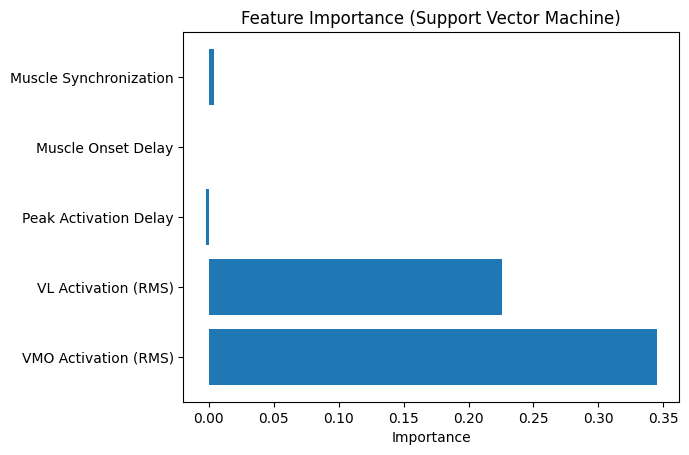

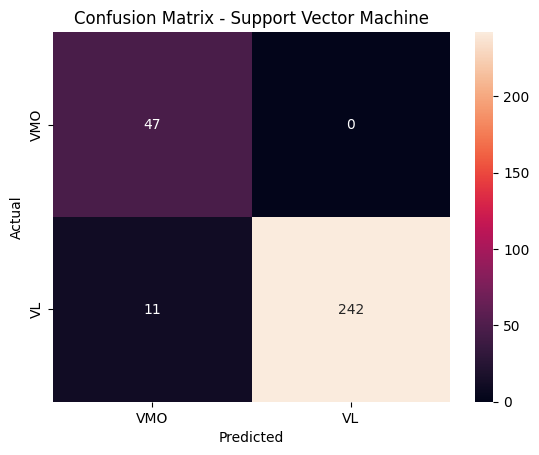


Class Distribution:
VL Dominant: 841 (84.3%)
VMO Dominant: 157 (15.7%)

Model : Support Vector Machine ()

Upload CSV file (any column names allowed)


KeyboardInterrupt: 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, balanced_accuracy_score
from sklearn.impute import SimpleImputer

# -----------------------------
# 1. LOAD DATA
# -----------------------------
sheet_id = "1jpnqHp_Eaq61QzrzK0xavPfnT9xddWWyMdb5OAhd5Iw"
gid = "1292720919"

url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=csv&gid={gid}"
df = pd.read_csv(url)

# -----------------------------
# 2. CLEAN DATA
# -----------------------------
df = df.drop(columns=["window_id", "start_index", "end_index"])
df = df.drop(columns=["RMS_ratio", "iEMG_ratio"])

# -----------------------------
# 3. LABELS
# -----------------------------
df["Status"] = df["Status"].str.strip().str.lower()

y = df["Status"].map({
    "vmo_dominant": 0,
    "vl_dominant": 1
})

X = df.drop(columns=["Status"])

# -----------------------------
# 4. HANDLE MISSING
# -----------------------------
imputer = SimpleImputer(strategy="mean")
X = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

# -----------------------------
# 5. SPLIT (WITH STRATIFY)
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y   #  added
)

# -----------------------------
# 6. SCALING
# -----------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# -----------------------------
# 7. SVM MODEL
# -----------------------------
model = SVC(
    kernel='rbf',
    C=100,
    gamma=0.01,
    class_weight='balanced',   #  handles imbalance
    probability=True
)

model.fit(X_train_scaled, y_train)

labels = ["VMO_dominant","VL_dominant"]

# -----------------------------
# 8. EVALUATION
# -----------------------------
preds = model.predict(X_test_scaled)

print("\nRESULTS")
print("Accuracy:", accuracy_score(y_test, preds))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, preds))  #  added

print("\nClassification Report:\n",
      classification_report(y_test, preds, target_names=labels))

cm = confusion_matrix(y_test, preds)

cm_df = pd.DataFrame(cm,
                     index=["Actual VMO", "Actual VL"],
                     columns=["Predicted VMO", "Predicted VL"])

print("\nConfusion Matrix:\n")
print(cm_df)

from sklearn.inspection import permutation_importance

# Compute importance
result = permutation_importance(
    model,
    X_test_scaled,
    y_test,
    n_repeats=10,
    random_state=42
)

importances = result.importances_mean

# Use same feature names as RF
feature_names = [
    "VMO Activation (RMS)",
    "VL Activation (RMS)",
    "Peak Activation Delay",
    "Muscle Onset Delay",
    "Muscle Synchronization"
]

# Plot (same style as your RF graph)
plt.figure()
plt.barh(feature_names, importances)
plt.title("Feature Importance (Support Vector Machine)")
plt.xlabel("Importance")
plt.show()
# -----------------------------
# 9. HEATMAP
# -----------------------------
plt.figure()
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=["VMO", "VL"],
            yticklabels=["VMO", "VL"])
plt.title("Confusion Matrix - Support Vector Machine")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# -----------------------------
# 10. CLASS DISTRIBUTION
# -----------------------------
total = len(y)
vl_count = (y == 1).sum()
vmo_count = (y == 0).sum()

print("\nClass Distribution:")
print(f"VL Dominant: {vl_count} ({vl_count/total:.1%})")
print(f"VMO Dominant: {vmo_count} ({vmo_count/total:.1%})")

print("\nModel : Support Vector Machine ()")


# ============================================================
#  11. RAW EMG PIPELINE (SAME AS RF)
# ============================================================

# ---- COLAB DETECTION ----
try:
    from google.colab import files
    COLAB = True
except:
    COLAB = False

# ---- INPUT ----
def get_user_emg():
    if COLAB:
        print("\nUpload CSV file (any column names allowed)")
        uploaded = files.upload()
        filename = list(uploaded.keys())[0]
    else:
        filename = input("Enter CSV file path: ")

    df_raw = pd.read_csv(filename)

    df_raw.columns = df_raw.columns.str.strip().str.lower()

    print("\nDetected columns:", df_raw.columns.tolist())
    print("\nPreview:\n", df_raw.head())

    numeric_cols = df_raw.select_dtypes(include=[np.number]).columns

    if len(numeric_cols) < 2:
        raise ValueError("CSV must contain at least 2 numeric columns")

    vmo_col = numeric_cols[0]
    vl_col  = numeric_cols[1]

    print(f"\nUsing columns → VMO: {vmo_col}, VL: {vl_col}")

    return df_raw[vmo_col].values, df_raw[vl_col].values


# ---- WINDOWING ----
def window_signal(signal, window_size=200, step=100):
    return [
        signal[i:i+window_size]
        for i in range(0, len(signal) - window_size + 1, step)
    ]


# ---- FEATURE EXTRACTION ----
def extract_features(vmo_win, vl_win):

    vmo_rect = np.abs(vmo_win)
    vl_rect  = np.abs(vl_win)

    vmo_rms = np.sqrt(np.mean(vmo_rect**2))
    vl_rms  = np.sqrt(np.mean(vl_rect**2))

    peak_delay = np.argmax(vl_rect) - np.argmax(vmo_rect)

    onset_vmo = np.argmax(vmo_rect > 0.1*np.max(vmo_rect))
    onset_vl  = np.argmax(vl_rect > 0.1*np.max(vl_rect))
    onset_delay = onset_vl - onset_vmo

    sync = np.corrcoef(vmo_rect, vl_rect)[0,1]

    return [vmo_rms, vl_rms, peak_delay, onset_delay, sync]


# ---- PREDICTION PIPELINE ----
def predict_from_raw():
    vmo_signal, vl_signal = get_user_emg()

    if len(vmo_signal) < 200:
        raise ValueError("Signal too short")

    vmo_windows = window_signal(vmo_signal)
    vl_windows  = window_signal(vl_signal)

    features = []

    for vmo_w, vl_w in zip(vmo_windows, vl_windows):
        features.append(extract_features(vmo_w, vl_w))

    if len(features) == 0:
        raise ValueError("No windows generated")

    features_df = pd.DataFrame(features, columns=X.columns)

    features_df = pd.DataFrame(imputer.transform(features_df), columns=X.columns)
    features_scaled = scaler.transform(features_df)

    preds = model.predict(features_scaled)

    #  Majority vote
    final_pred = np.bincount(preds).argmax()

    label_map = {
        0: "VMO Dominant",
        1: "VL Dominant ( Possible PFPS Risk)"
    }

    print("\nTotal windows:", len(preds))
    print("\nFINAL PREDICTION:", label_map[final_pred])


# -----------------------------
# RUN
# -----------------------------
predict_from_raw()